# Разведочный анализ данных (EDA): MovieLens

Цель: изучить структуру и качество данных для рекомендательной системы фильмов, выбрать даты временного разбиения и сформулировать требования к качеству данных.

Датасет и параметры берутся из `configs/params.yaml`. Все графики сохраняются в `reports/figures/` для вставки в отчёт.

## 0. Настройка

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
params = yaml.safe_load((ROOT / "configs" / "params.yaml").read_text(encoding="utf-8"))

DATASET = params["dataset"]
THRESHOLD = params["relevance_threshold"]
SEED = params["seed"]
np.random.seed(SEED)

DATA_DIR = ROOT / "data" / "raw" / DATASET
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print("Датасет:", DATASET)
print("Папка с данными:", DATA_DIR)

Датасет: ml-25m
Папка с данными: C:\kursovaya\movielens-recsys\data\raw\ml-25m


## 1. Загрузка данных

In [ ]:
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
links = pd.read_csv(DATA_DIR / "links.csv")

for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]:
    mem = df.memory_usage(deep=True).sum() / 1024**2
    print(f"{name:8s} строк: {len(df):>10,}  столбцов: {df.shape[1]}  память: {mem:.1f} МБ")

ratings  строк: 25,000,095  столбцов: 4  память: 762.9 МБ
movies   строк:     62,423  столбцов: 3  память: 3.7 МБ
tags     строк:  1,093,360  столбцов: 4  память: 44.6 МБ
links    строк:     62,423  столбцов: 3  память: 1.4 МБ


In [ ]:
display(ratings.head())
display(movies.head())
ratings.dtypes

,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Время оценки хранится в секундах от 1970 года (Unix time). Переведём его в дату.

In [ ]:
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
tags["datetime"] = pd.to_datetime(tags["timestamp"], unit="s")
print("Первая оценка:", ratings["datetime"].min())
print("Последняя оценка:", ratings["datetime"].max())

Первая оценка: 1995-01-09 11:46:49
Последняя оценка: 2019-11-21 09:15:03


## 2. Проверка качества данных

In [ ]:
checks = {}

# пропуски
checks["Пропуски в ratings"] = int(ratings.isna().sum().sum())
checks["Пропуски в movies"] = int(movies.isna().sum().sum())
checks["Пропуски в links (tmdbId и др.)"] = int(links.isna().sum().sum())

# дубликаты
checks["Полные дубликаты строк ratings"] = int(ratings.duplicated().sum())
checks["Повторные оценки пары user-movie"] = int(ratings.duplicated(["userId", "movieId"]).sum())
checks["Дубликаты movieId в movies"] = int(movies["movieId"].duplicated().sum())

# диапазон и шаг оценок
checks["Оценки вне диапазона 0.5-5"] = int((~ratings["rating"].between(0.5, 5)).sum())
checks["Оценки не кратные 0.5"] = int(((ratings["rating"] * 2) % 1 != 0).sum())

# ссылочная целостность
checks["Оценки фильмов, которых нет в movies"] = int((~ratings["movieId"].isin(movies["movieId"])).sum())
checks["Фильмы без единой оценки"] = int((~movies["movieId"].isin(ratings["movieId"])).sum())

# метаданные фильмов
checks["Фильмы без жанров"] = int((movies["genres"] == "(no genres listed)").sum())
movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)\s*$")[0], errors="coerce")
checks["Фильмы без года в названии"] = int(movies["year"].isna().sum())
checks["Повторяющиеся названия фильмов"] = int(movies["title"].duplicated().sum())

# время
checks["Оценки с датой в будущем"] = int((ratings["datetime"] > pd.Timestamp.now()).sum())

quality = pd.DataFrame({"Проверка": checks.keys(), "Найдено": checks.values()})
quality["Статус"] = np.where(quality["Найдено"] == 0, "OK", "Внимание")
quality

,Проверка,Найдено,Статус
0,Пропуски в ratings,0,OK
1,Пропуски в movies,0,OK
2,Пропуски в links (tmdbId и др.),107,Внимание
3,Полные дубликаты строк ratings,0,OK
4,Повторные оценки пары user-movie,0,OK
5,Дубликаты movieId в movies,0,OK
6,Оценки вне диапазона 0.5-5,0,OK
7,Оценки не кратные 0.5,0,OK
8,"Оценки фильмов, которых нет в movies",0,OK
9,Фильмы без единой оценки,3376,Внимание


Строки со статусом «Внимание» не обязательно ошибки. Например, фильмы без оценок или без жанров — нормальная ситуация для каталога, но их нужно учесть при обучении и в резервной стратегии. Посмотрим на найденные случаи подробнее.

In [ ]:
dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
display(dup_titles.head(10))
display(movies[movies["year"].isna()].head(10))

,movieId,title,genres,year
13713,71057,9 (2009),Adventure|Animation|Sci-Fi,2009.0
61103,204982,9 (2009),Comedy,2009.0
30628,136696,Absolution (2015),Action|Adventure|Crime|Thriller,2015.0
37060,151797,Absolution (2015),Drama|Thriller,2015.0
580,588,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,1992.0
22286,114240,Aladdin (1992),Adventure|Animation|Children|Comedy|Fantasy,1992.0
50683,181565,Alone (2017),Fantasy|Sci-Fi,2017.0
58489,198719,Alone (2017),(no genres listed),2017.0
61714,206712,American Woman (2019),(no genres listed),2019.0
61913,207249,American Woman (2019),Drama,2019.0


,movieId,title,genres,year
15036,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller,NaN
18789,98063,Mona and the Time of Burning Love (Mona ja pal...,Drama,NaN
25387,123619,Terrible Joe Moran,(no genres listed),NaN
26284,125571,The Court-Martial of Jackie Robinson,(no genres listed),NaN
26309,125632,In Our Garden,(no genres listed),NaN
26392,125958,Stephen Fry In America - New World,(no genres listed),NaN
26576,126438,Two: The Story of Roman & Nyro,Documentary|Drama,NaN
26699,127005,A Year Along the Abandoned Road,(no genres listed),NaN
27216,128612,Body/Cialo,Comedy|Drama|Mystery,NaN
27269,128734,Polskie gówno,Comedy|Musical,NaN


## 3. Общие характеристики и разреженность

In [ ]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)
density = n_ratings / (n_users * n_movies)

summary = pd.Series({
    "Пользователей": n_users,
    "Фильмов с оценками": n_movies,
    "Фильмов в каталоге": movies["movieId"].nunique(),
    "Оценок": n_ratings,
    "Заполненность матрицы, %": round(density * 100, 3),
    "Разреженность, %": round((1 - density) * 100, 3),
    "Оценок на пользователя (медиана)": ratings.groupby("userId").size().median(),
    "Оценок на фильм (медиана)": ratings.groupby("movieId").size().median(),
})
summary.to_frame("Значение")

,Значение
Пользователей,162541.00
Фильмов с оценками,59047.00
Фильмов в каталоге,62423.00
Оценок,25000095.00
"Заполненность матрицы, %",0.26
"Разреженность, %",99.74
Оценок на пользователя (медиана),71.00
Оценок на фильм (медиана),6.00


## 4. Распределение оценок

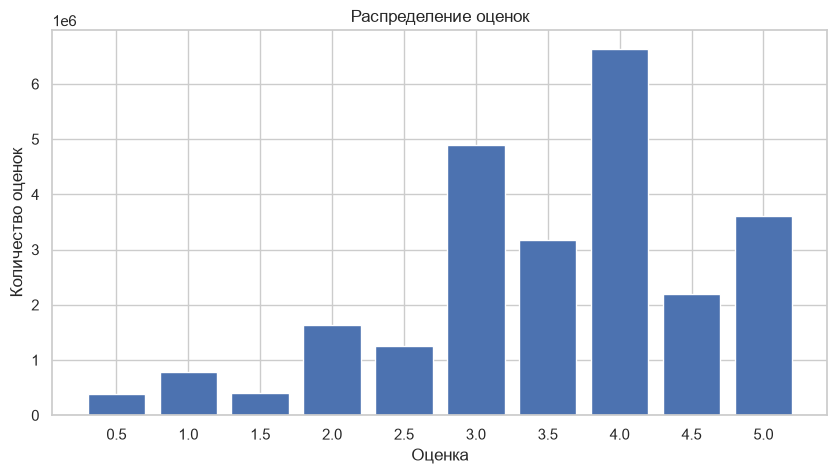

Средняя оценка: 3.53
Доля «релевантных» оценок (>= 4.0): 49.8%


Доля целых оценок: 70.3%


In [ ]:
fig, ax = plt.subplots()
counts = ratings["rating"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
ax.set_xlabel("Оценка")
ax.set_ylabel("Количество оценок")
ax.set_title("Распределение оценок")
save(fig, "01_rating_distribution")
plt.show()

share_rel = (ratings["rating"] >= THRESHOLD).mean()
print(f"Средняя оценка: {ratings['rating'].mean():.2f}")
print(f"Доля «релевантных» оценок (>= {THRESHOLD}): {share_rel:.1%}")
print(f"Доля целых оценок: {(ratings['rating'] % 1 == 0).mean():.1%}")

## 5. Активность пользователей и популярность фильмов

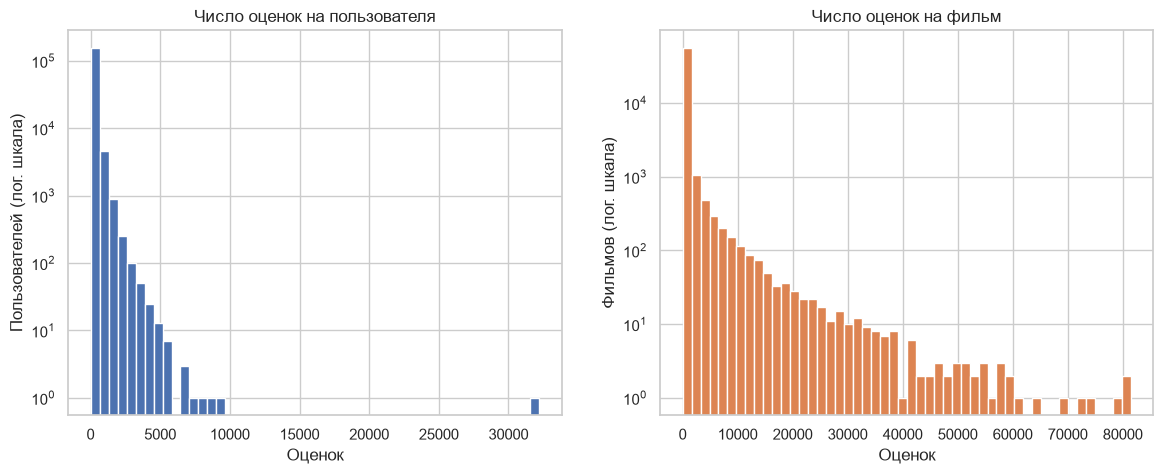

,На пользователя,На фильм
count,162541.0,59047.0
mean,153.8,423.4
std,268.0,2477.9
min,20.0,1.0
25%,36.0,2.0
50%,71.0,6.0
75%,162.0,36.0
max,32202.0,81491.0


In [ ]:
user_cnt = ratings.groupby("userId").size()
movie_cnt = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(user_cnt, bins=50, color="#4C72B0", log=True)
axes[0].set_title("Число оценок на пользователя")
axes[0].set_xlabel("Оценок")
axes[0].set_ylabel("Пользователей (лог. шкала)")
axes[1].hist(movie_cnt, bins=50, color="#DD8452", log=True)
axes[1].set_title("Число оценок на фильм")
axes[1].set_xlabel("Оценок")
axes[1].set_ylabel("Фильмов (лог. шкала)")
save(fig, "02_activity_popularity")
plt.show()

pd.DataFrame({"На пользователя": user_cnt.describe(), "На фильм": movie_cnt.describe()}).round(1)

### «Длинный хвост»: какую долю оценок собирают самые популярные фильмы

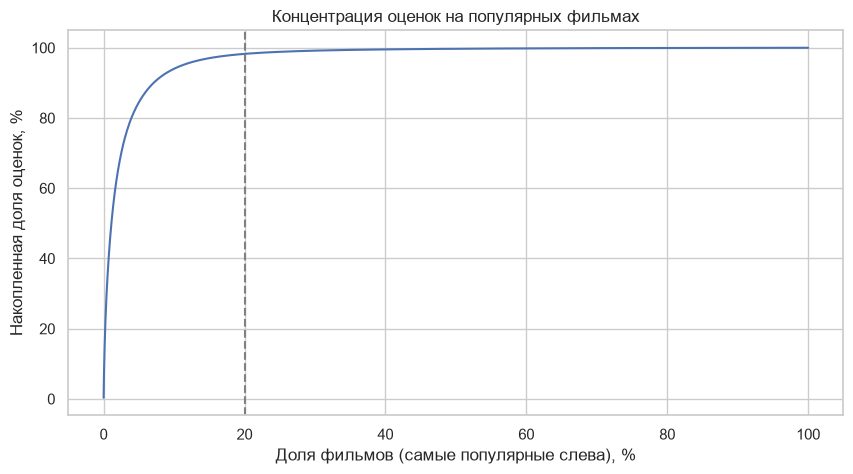

20% самых популярных фильмов собирают 98.3% всех оценок
Фильмов с < 2 оценками: 17.4%
Фильмов с < 6 оценками: 48.8%
Фильмов с < 11 оценками: 60.4%
Пользователей с < 20 оценками: 0.0%


In [ ]:
sorted_cnt = movie_cnt.sort_values(ascending=False).to_numpy()
cum_share = sorted_cnt.cumsum() / sorted_cnt.sum()
movie_share = np.arange(1, len(sorted_cnt) + 1) / len(sorted_cnt)

fig, ax = plt.subplots()
ax.plot(movie_share * 100, cum_share * 100, color="#4C72B0")
ax.axvline(20, ls="--", color="grey")
ax.set_xlabel("Доля фильмов (самые популярные слева), %")
ax.set_ylabel("Накопленная доля оценок, %")
ax.set_title("Концентрация оценок на популярных фильмах")
save(fig, "03_long_tail")
plt.show()

top20 = cum_share[int(len(sorted_cnt) * 0.2) - 1]
print(f"20% самых популярных фильмов собирают {top20:.1%} всех оценок")
for k in [1, 5, 10]:
    print(f"Фильмов с < {k + 1} оценками: {(movie_cnt <= k).mean():.1%}")
print(f"Пользователей с < 20 оценками: {(user_cnt < 20).mean():.1%}")

## 6. Динамика во времени и выбор дат разбиения

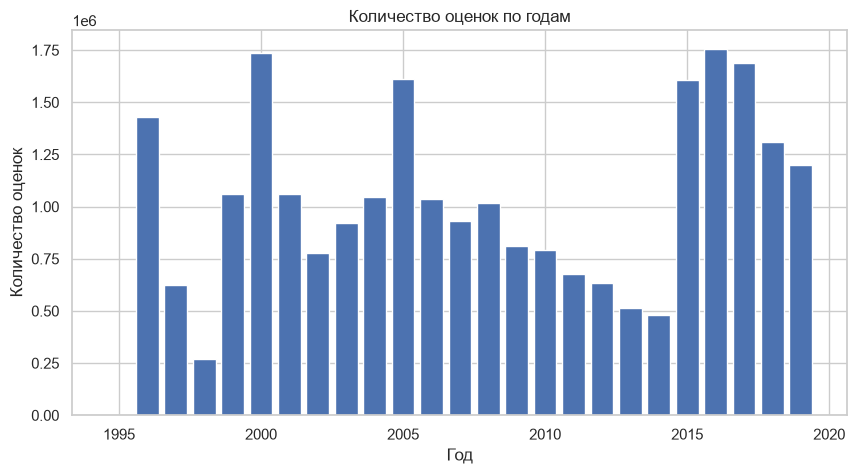

,оценок,пользователей,средняя_оценка
datetime,,,
1995,3,1,3.67
1996,1430093,23028,3.55
1997,626202,10014,3.59
1998,272099,3315,3.51
1999,1059080,8387,3.62
2000,1735398,13303,3.58
2001,1058750,9300,3.53
2002,776654,7098,3.49
2003,920295,7674,3.48


In [ ]:
by_year = ratings.groupby(ratings["datetime"].dt.year).agg(
    оценок=("rating", "size"),
    пользователей=("userId", "nunique"),
    средняя_оценка=("rating", "mean"),
)

fig, ax = plt.subplots()
ax.bar(by_year.index, by_year["оценок"], color="#4C72B0")
ax.set_xlabel("Год")
ax.set_ylabel("Количество оценок")
ax.set_title("Количество оценок по годам")
save(fig, "04_ratings_by_year")
plt.show()

by_year.round(2)

Даты разбиения выбираем по квантилям времени: первые 80% оценок — обучение, следующие 10% — валидация, последние 10% — тест. Затем проверяем, сколько пользователей и фильмов в валидации и тесте модель ни разу не видела при обучении (холодный старт).

In [ ]:
val_date = ratings["datetime"].quantile(0.8)
test_date = ratings["datetime"].quantile(0.9)

train = ratings[ratings["datetime"] < val_date]
val = ratings[(ratings["datetime"] >= val_date) & (ratings["datetime"] < test_date)]
test = ratings[ratings["datetime"] >= test_date]

def cold_share(part, known):
    users = part["userId"].isin(known["userId"])
    items = part["movieId"].isin(known["movieId"])
    return pd.Series({
        "оценок": len(part),
        "пользователей": part["userId"].nunique(),
        "новых пользователей, %": round((~part.drop_duplicates("userId")["userId"].isin(known["userId"])).mean() * 100, 1),
        "оценок от новых пользователей, %": round((~users).mean() * 100, 1),
        "оценок новых фильмов, %": round((~items).mean() * 100, 1),
    })

split_info = pd.DataFrame({
    "train": pd.Series({"оценок": len(train), "пользователей": train["userId"].nunique()}),
    "validation": cold_share(val, train),
    "test": cold_share(test, pd.concat([train, val])),
})
print("val_date: ", val_date.date())
print("test_date:", test_date.date())
split_info

val_date:  2016-06-25
test_date: 2018-01-04


,train,validation,test
"новых пользователей, %",NaN,70.6,64.8
оценок,20000075.0,2500010.0,2500010.0
"оценок новых фильмов, %",NaN,4.8,5.8
"оценок от новых пользователей, %",NaN,82.9,79.0
пользователей,137883.0,18003.0,18442.0


Найденные даты нужно записать в `configs/params.yaml` (поля `split.val_date` и `split.test_date`). Если доля оценок от новых пользователей в тесте очень велика, это важный вывод: значительная часть теста — холодный старт, и резервная стратегия будет работать часто.

## 7. Жанры

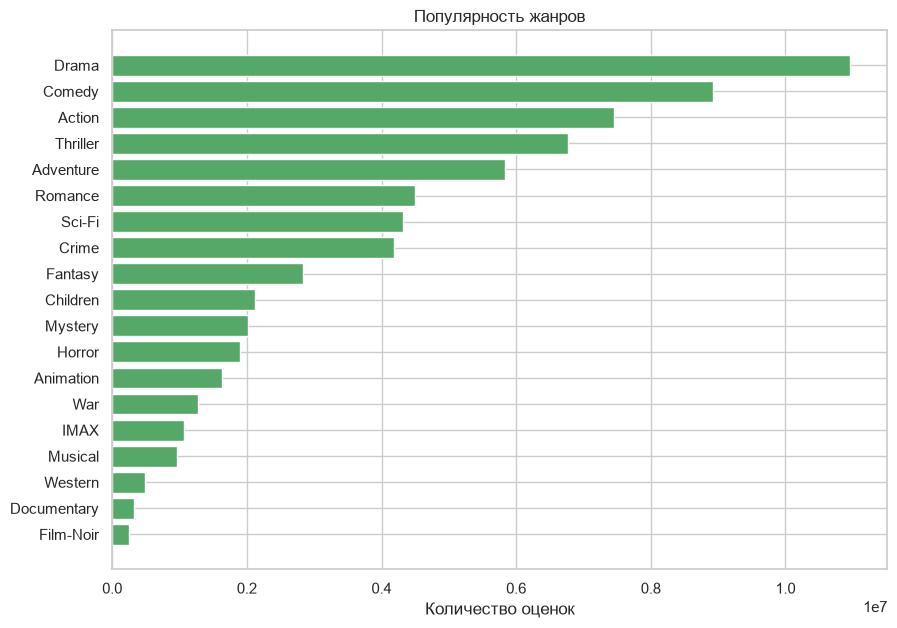

Жанров на фильм в среднем: 1.8


,оценок,средняя_оценка,фильмов
genre,,,
Drama,10962833,3.68,25606
Comedy,8926230,3.42,16870
Action,7446918,3.47,7348
Thriller,6763272,3.52,8654
Adventure,5832424,3.52,4145
Romance,4497291,3.54,7719
Sci-Fi,4325740,3.48,3595
Crime,4190259,3.69,5319
Fantasy,2831585,3.51,2731


In [ ]:
genres = movies.assign(genre=movies["genres"].str.split("|")).explode("genre")
genres = genres[genres["genre"] != "(no genres listed)"]

genre_stats = (
    ratings.merge(genres[["movieId", "genre"]], on="movieId")
    .groupby("genre")
    .agg(оценок=("rating", "size"), средняя_оценка=("rating", "mean"))
    .join(genres.groupby("genre").size().rename("фильмов"))
    .sort_values("оценок", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(genre_stats.index[::-1], genre_stats["оценок"][::-1], color="#55A868")
ax.set_xlabel("Количество оценок")
ax.set_title("Популярность жанров")
save(fig, "05_genres")
plt.show()

print("Жанров на фильм в среднем:", round(movies["genres"].str.count(r"\|").add(1).mean(), 2))
genre_stats.round(2)

## 8. Теги

In [ ]:
print("Всего тегов:", len(tags))
print("Уникальных тегов:", tags["tag"].nunique())
print("Пользователей, ставивших теги:", tags["userId"].nunique(), "из", n_users)
tags["tag"].str.lower().value_counts().head(15)

Всего тегов: 1093360


Уникальных тегов: 73050


Пользователей, ставивших теги: 14592 из 162541


tag
sci-fi                8795
atmospheric           7053
action                6783
comedy                6366
surreal               5584
funny                 5354
based on a book       5194
twist ending          4904
visually appealing    4691
romance               4458
dystopia              4329
dark comedy           4133
quirky                3999
bd-r                  3966
thought-provoking     3847
Name: count, dtype: int64

## 9. Итоговая сводка

In [ ]:
final = pd.Series({
    "Датасет": DATASET,
    "Пользователей": n_users,
    "Фильмов с оценками": n_movies,
    "Оценок": n_ratings,
    "Разреженность, %": round((1 - density) * 100, 2),
    "Средняя оценка": round(ratings["rating"].mean(), 2),
    f"Доля оценок >= {THRESHOLD}, %": round(share_rel * 100, 1),
    "Доля оценок у топ-20% фильмов, %": round(top20 * 100, 1),
    "Период": f"{ratings['datetime'].min().date()} — {ratings['datetime'].max().date()}",
    "val_date": str(val_date.date()),
    "test_date": str(test_date.date()),
})
final.to_frame("Значение")

,Значение
Датасет,ml-25m
Пользователей,162541
Фильмов с оценками,59047
Оценок,25000095
"Разреженность, %",99.74
Средняя оценка,3.53
"Доля оценок >= 4.0, %",49.8
"Доля оценок у топ-20% фильмов, %",98.3
Период,1995-01-09 — 2019-11-21
val_date,2016-06-25


## 10. Выводы и требования к качеству данных

### Выводы (ml-25m)

1. **Масштаб и разреженность.** 25 000 095 оценок, 162 541 пользователь, 59 047 фильмов с оценками, период 1995–2019. Разреженность матрицы 99,74 %; медиана — 71 оценка на пользователя и 6 на фильм.
2. **Оценки.** Средняя 3,53, распределение смещено к высоким значениям. Доля оценок ≥ 4 — 49,8 %, классы сбалансированы.
3. **Активность.** У каждого пользователя не менее 20 оценок (датасет отфильтрован). Максимум — 32 202 оценки у одного пользователя: вероятная аномалия, требует проверки.
4. **Длинный хвост.** 20 % популярных фильмов собирают 98,3 % оценок (в ml-latest-small — 77 %). 48,8 % фильмов имеют ≤ 5 оценок, но в сумме это < 0,6 % всех оценок, поэтому их можно исключить из обучения почти без потери данных. Coverage контролировать обязательно.
5. **Время.** Активность и средняя оценка меняются по годам (средняя от 3,43 до 3,65) — наблюдаемый дрейф. 1995 год (3 оценки) — артефакт.
6. **Качество.** Критических нарушений нет. Особенности: 3 376 фильмов без оценок, 5 062 без жанров, 412 без года, 98 повторяющихся названий (проверять по imdbId, не все — дубликаты).
7. **Разбиение.** Глобальное разбиение 80/10/10: val_date = 2016-06-25, test_date = 2018-01-04. Но 79–83 % оценок валидации и теста — от новых пользователей, то есть это фактически холодный старт. **Решение:** основная валидация — временное разбиение внутри истории каждого пользователя; глобальное — отдельный сценарий для холодного старта.
8. **Версии датасета.** ml-latest-small недооценивает разреженность и эффект популярности, поэтому итоговые эксперименты проводятся на ml-25m.

### Требования к качеству данных

1. `userId`, `movieId`, `rating`, `timestamp` без пропусков; идентификаторы — положительные целые.
2. `rating` в диапазоне 0,5–5,0, кратен 0,5.
3. Пара `userId`–`movieId` уникальна.
4. Каждый `movieId` из ratings есть в movies.
5. `timestamp` не позже даты выгрузки; единичные оценки 1995 года — артефакт.
6. `movieId` в movies уникален; фильмы без жанров помечаются для резервной стратегии.
7. Фильмы с одинаковым imdbId объединяются до обучения.
8. В обучении: фильмы с ≥ N оценками (N ≈ 5), пользователи с ≥ 20 оценками.
9. Пользователи выше 99,9-го перцентиля активности проверяются на аномальность.
10. При каждом разбиении контролируется доля новых пользователей и фильмов.